In [109]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer

# Importação do dataset

In [110]:
df = pd.read_csv('../data/dados_clientes.csv')
df.head(10)

,idade,renda,score_credito,categoria,educacao,estado_civil
0,40.960570,44341.562353,582.482173,C,Pós-graduação,Solteiro
1,33.340828,34972.483357,635.548133,D,Fundamental,Casado
2,42.772262,22693.077136,570.758008,A,Superior,Solteiro
3,53.276358,15939.117886,619.203847,D,Médio,Solteiro
4,32.190160,NaN,460.638533,B,Fundamental,Solteiro
5,32.190357,26815.696697,671.329371,B,Pós-graduação,Divorciado
6,53.950554,34461.450794,650.120548,A,Médio,Casado
7,44.209217,30260.118423,568.291137,A,Superior,Casado
8,29.366307,37226.507647,715.924567,C,Fundamental,Solteiro
9,41.510721,16854.658969,743.757014,B,Superior,Divorciado


# Análise Exploratória (EDA)

In [111]:
print("-- INFORMAÇÕES GERAIS --")
print(f"Shape: {df.shape}")
print(f"\nTipos de dados:")
print(df.dtypes)

print("\n-- INFORMAÇÕES DETALHADAS --")
df.info()

-- INFORMAÇÕES GERAIS --
Shape: (1015, 6)

Tipos de dados:
idade            float64
renda            float64
score_credito    float64
categoria            str
educacao             str
estado_civil         str
dtype: object

-- INFORMAÇÕES DETALHADAS --
<class 'pandas.DataFrame'>
RangeIndex: 1015 entries, 0 to 1014
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   idade          1015 non-null   float64
 1   renda          965 non-null    float64
 2   score_credito  985 non-null    float64
 3   categoria      1015 non-null   str    
 4   educacao       995 non-null    str    
 5   estado_civil   1015 non-null   str    
dtypes: float64(3), str(3)
memory usage: 47.7 KB


In [112]:
print("-- ESTATÍSTICAS DESCRITIVAS --")
df.describe()

-- ESTATÍSTICAS DESCRITIVAS --


,idade,renda,score_credito
count,1015.000000,965.000000,985.000000
mean,35.338857,26819.203391,650.933969
std,12.224203,16751.643623,98.272337
min,-3.895208,5063.461821,348.048784
25%,27.179381,16271.046818,586.269225
50%,35.294122,23021.951278,650.052796
75%,42.834541,32191.711607,715.924567
max,81.232778,193389.784073,1042.623771


In [113]:
print("-- QUANTIDADE DE VALORES FALTANTES --")
missing_data = df.isnull().sum()
missing_percent = (missing_data / len(df)) * 100

missing_df = pd.DataFrame({
    'Qtd Faltante': missing_data,
    'Percentual': missing_percent
})

print(missing_df[missing_df['Qtd Faltante'] > 0])

-- QUANTIDADE DE VALORES FALTANTES --
               Qtd Faltante  Percentual
renda                    50    4.926108
score_credito            30    2.955665
educacao                 20    1.970443


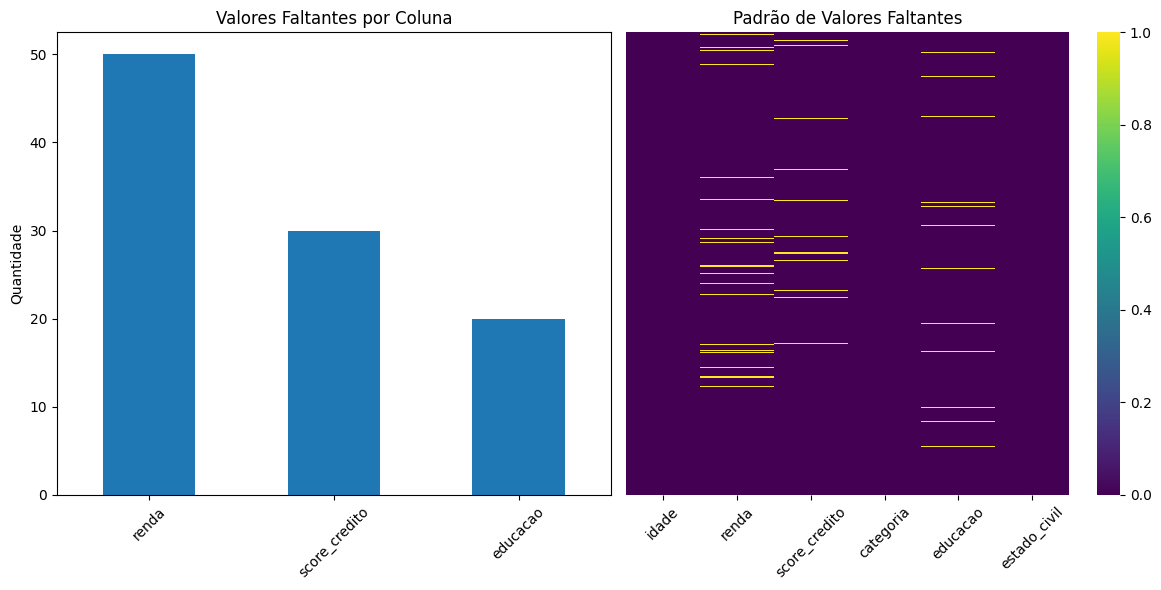

In [114]:
plt.figure(figsize=(12, 6))

plt.subplot(1,2,1)
missing_data[missing_data > 0].plot(kind='bar')
plt.title('Valores Faltantes por Coluna')
plt.ylabel('Quantidade')
plt.xticks(rotation=45)

plt.subplot(1,2,2)
sns.heatmap(df.isnull(), cbar=True, yticklabels=False, cmap='viridis')
plt.title('Padrão de Valores Faltantes')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

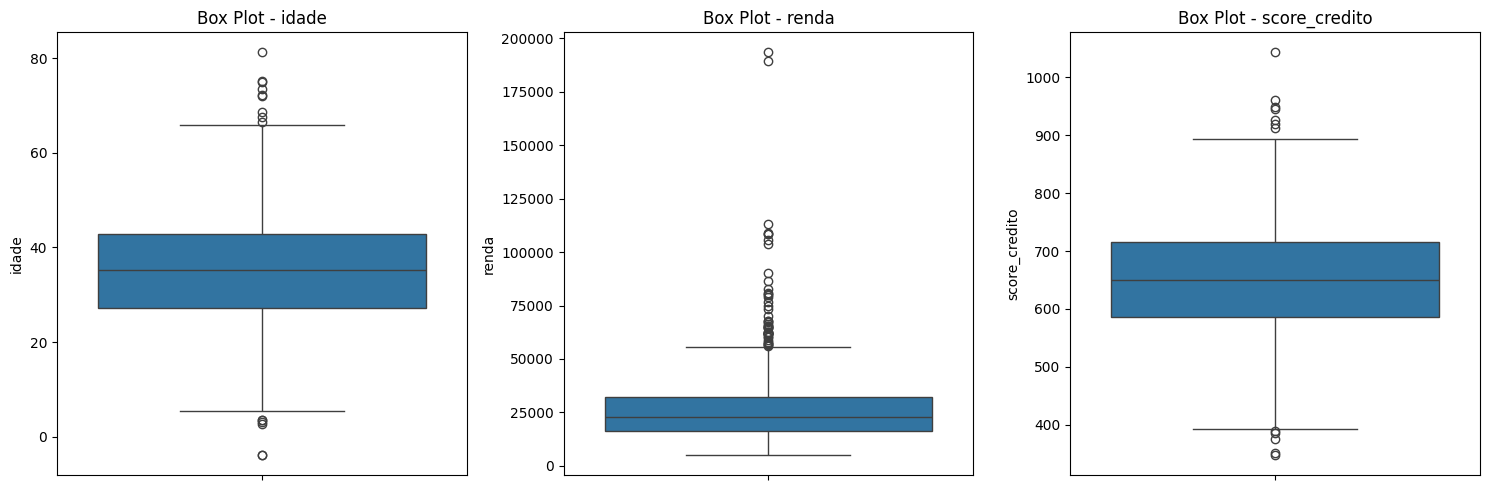

In [115]:
numeric_cols = ['idade', 'renda', 'score_credito']

plt.figure(figsize=(15, 5))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f"Box Plot - {col}")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

# Tratamento

In [116]:
def detect_outliers_iqr(df, col):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]

    return outliers, lower_bound, upper_bound


print('-- DETECÇÃO DE OUTLIERS (MÉTODO IQR) --')
for col in numeric_cols:
    outliers, lower, upper = detect_outliers_iqr(df, col)

    print(f"\n{col}")
    print(f"  - Outliers: {len(outliers)}  ({(len(outliers)/len(df)*100):.1f}%)")
    print(f"  - Limites: [{lower:.2f}, {upper:.2f}]")
    
    if len(outliers) > 0:
        print(f"  - Valores extremos: {outliers[col].min():.2f} a {outliers[col].max():.2f}")

-- DETECÇÃO DE OUTLIERS (MÉTODO IQR) --

idade
  - Outliers: 15  (1.5%)
  - Limites: [3.70, 66.32]
  - Valores extremos: -3.90 a 81.23

renda
  - Outliers: 47  (4.6%)
  - Limites: [-7609.95, 56072.71]
  - Valores extremos: 56198.70 a 193389.78

score_credito
  - Outliers: 12  (1.2%)
  - Limites: [391.79, 910.41]
  - Valores extremos: 348.05 a 1042.62


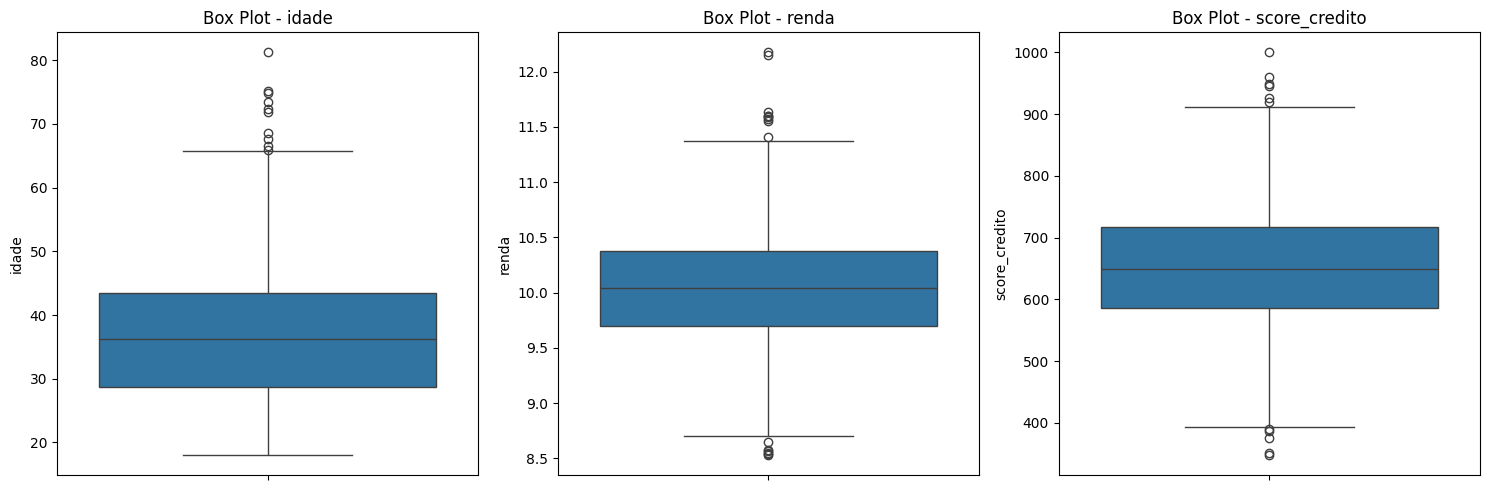

In [117]:
df = df[df['idade'] >= 18] # IDADE MINIMA NO BRASIL PARA CARTÃO DE CRÉDITO
df['score_credito'] = df['score_credito'].clip(lower=0, upper=1000)
df['renda'] = np.log1p(df['renda'])

numeric_cols = ['idade', 'renda', 'score_credito']

plt.figure(figsize=(15, 5))
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(1, 3, i)
    sns.boxplot(y=df[col])
    plt.title(f"Box Plot - {col}")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [118]:
print("-- ANÁLISE DE DUPLICATAS --")
print(f"Total de registros: {len(df)}")
print(f"Registros únicos: {len(df.drop_duplicates())}")
print(f"Duplicatas encontradas: {len(df) - len(df.drop_duplicates())}")

df_final = df.drop_duplicates().reset_index(drop=True)

print(f"\nDataset final limpo: {df_final.shape}")

-- ANÁLISE DE DUPLICATAS --
Total de registros: 944
Registros únicos: 933
Duplicatas encontradas: 11

Dataset final limpo: (933, 6)


In [119]:
cols_num = ['idade', 'renda', 'score_credito']
cols_ord = ['categoria', 'educacao']
cols_nom = ['estado_civil']

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

ord_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordnal', OrdinalEncoder())
])

nom_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num_transform', num_pipeline, cols_num),
    ('ord_transform', ord_pipeline, cols_ord),
    ('nom_transform', nom_pipeline, cols_nom)
])

pipeline = Pipeline([
    ('preprocessor', preprocessor)
    # PRONTO PARA OS PRÓXIMOS PASSOS
])

dados_array = pipeline.fit_transform(df)

colunas_finais = pipeline.get_feature_names_out()
df_processado = pd.DataFrame(dados_array, columns=colunas_finais)

df_processado.head(10)

,num_transform__idade,num_transform__renda,num_transform__score_credito,ord_transform__categoria,ord_transform__educacao,nom_transform__estado_civil_Casado,nom_transform__estado_civil_Divorciado,nom_transform__estado_civil_Solteiro
0,0.362955,0.595667,0.359587,2.0,2.0,0.0,0.0,1.0
1,0.242422,0.530504,0.440983,3.0,0.0,1.0,0.0,0.0
2,0.391613,0.411770,0.341604,0.0,3.0,0.0,0.0,1.0
3,0.557772,0.314784,0.415913,3.0,1.0,0.0,0.0,1.0
4,0.224221,0.415564,0.172697,1.0,0.0,0.0,0.0,1.0
5,0.224224,0.457596,0.495866,1.0,2.0,0.0,1.0,0.0
6,0.568437,0.526463,0.463335,0.0,1.0,1.0,0.0,0.0
7,0.414344,0.490771,0.337820,0.0,3.0,1.0,0.0,0.0
8,0.179552,0.547651,0.564269,2.0,0.0,0.0,0.0,1.0
9,0.371658,0.330117,0.606960,1.0,3.0,0.0,1.0,0.0
